# Passo 4 – Candle × janela de treino × frequência de re-treino

"Quanto a árvore olha para trás" no sentido de **histórico**: com quantos meses ela aprende e de quanto em quanto tempo ela é re-treinada.

* Variáveis: 5 lags + todos os grupos (Passo 3). RF moderada fixa (300 árvores, prof. 6, folha 0,5%).
* Alvo: retorno do próximo candle em %, **sem custo** no treino.
* Tudo medido na **validação 2024**, simulando a vida real: em cada data de re-treino o modelo só conhece os últimos N meses.

Duas partes:
1. **Diagnóstico** – o modelo envelhece? (justifica testar a frequência de re-treino)
2. **Grade** – 4 candles × 4 janelas × 3 frequências (+ 1 min trimestral como referência).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os, time
import rf_zero as rz
win_1m = rz.carregar("../../dados/WINN_M1/WIN$N_M1.csv")
os.makedirs("saidas", exist_ok=True)
bases = {m: rz.montar_base(win_1m, m) for m in [1, 5, 15, 30, 60]}

## 4.1 O modelo envelhece?

Treinamos o modelo em vários momentos (início de cada trimestre de 2022 a 2024, janela de 12 meses) e medimos o **ganho bruto em cada um dos 6 meses seguintes**, sem re-treinar.
Depois tiramos a média por "meses desde o treino". Se a curva cai, o padrão aprendido perde validade com o tempo → re-treinar com mais frequência ajuda.

In [2]:
ancoras = pd.date_range("2022-01-01", "2024-07-01", freq="QS")
env = []
for m in [15, 60]:
    base, cols = bases[m]
    for a in ancoras:
        tr = base[(base.index >= a - pd.DateOffset(months=12)) & (base.index < a)]
        te = base[(base.index >= a) & (base.index < a + pd.DateOffset(months=6))]
        rf = rz.rf_padrao(len(tr)).fit(tr[cols], tr["ret_prox"])
        p = rf.predict(te[cols])
        mes = (te.index.year - a.year) * 12 + (te.index.month - a.month) + 1
        df = pd.DataFrame({"candle": f"{m} min", "ancora": a, "mes": mes,
                           "bruto": np.sign(p) * te["mov_prox"].values,
                           "acerto": np.sign(p) == np.sign(te["ret_prox"].values)})
        env.append(df[te["ret_prox"].values != 0])
env = pd.concat(env)
curva = env.groupby(["candle", "mes"]).agg(bruto_pts=("bruto", "mean"), acerto_pct=("acerto", "mean"))
curva["acerto_pct"] *= 100
curva.unstack(0).round(2)

bruto_pts        acerto_pct       
candle    15 min 60 min     15 min 60 min
mes                                      
1          -0.13  -7.65      50.26  49.20
2          -1.09   8.12      49.44  50.46
3           0.19   4.38      50.26  51.76
4          -3.23   6.45      49.49  51.48
5           1.04   4.79      50.28  52.25
6          -0.26  43.91      49.50  54.11

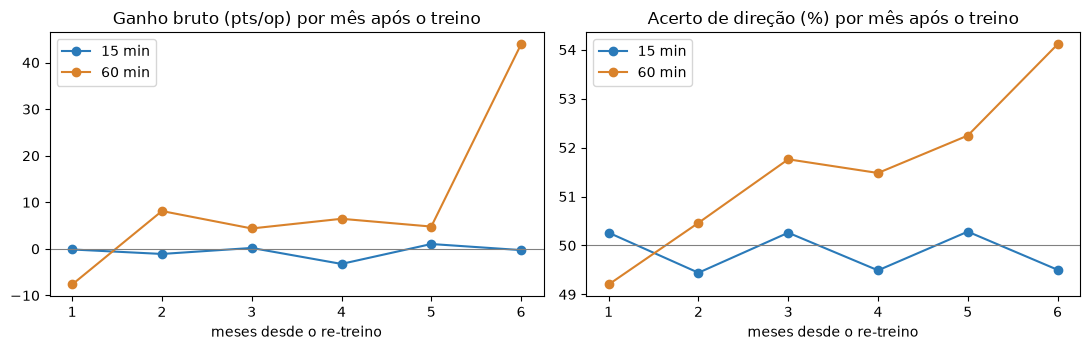

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for c, cor in zip(["15 min", "60 min"], ["#2a7ab9", "#d9822b"]):
    curva.loc[c, "bruto_pts"].plot(ax=axs[0], marker="o", color=cor, label=c)
    curva.loc[c, "acerto_pct"].plot(ax=axs[1], marker="o", color=cor, label=c)
axs[0].axhline(0, color="gray", lw=.8); axs[0].set_title("Ganho bruto (pts/op) por mês após o treino")
axs[1].axhline(50, color="gray", lw=.8); axs[1].set_title("Acerto de direção (%) por mês após o treino")
for a in axs: a.set_xlabel("meses desde o re-treino"); a.legend()
plt.tight_layout(); plt.savefig("passo04_envelhecimento.png", dpi=120); plt.show()

## 4.2 A grade

Para cada combinação mostramos lado a lado:
* **Sinal (sem custo):** R², acerto, ganho bruto por operação e seu t, trimestres de 2024 com ganho bruto positivo;
* **Dinheiro (com custo de 5 pts):** líquido operando em todo candle e líquido operando só nos 20% de previsões mais fortes (prévia do Passo 5).

**Critério de escolha** (definido no Passo 1, aplicado ao ganho bruto porque o custo só entra no Passo 5):
candidata = ganho bruto > 0, **t ≥ 2** e positivo em **≥ 3 de 4 trimestres**; entre as candidatas, maior ganho bruto por operação.

In [4]:
ARQ = "saidas/passo04_previsoes.pkl"
FREQS = {"mensal": "MS", "trimestral": "QS", "semestral": "6MS"}
combos = [(m, j, f) for m in [5, 15, 30, 60] for j in [3, 6, 12, 24] for f in FREQS] + \
         [(1, j, "trimestral") for j in [3, 6, 12, 24]]
prevs = pd.read_pickle(ARQ) if os.path.exists(ARQ) else {}
t0 = time.time()
for m, j, f in combos:
    if (m, j, f) in prevs: continue
    base, cols = bases[m]
    prevs[(m, j, f)] = rz.walk_forward(base, cols, rz.VALIDACAO, j, FREQS[f])[["prev", "ret_prox", "mov_prox", "close"]]
    pd.to_pickle(prevs, ARQ)
print(f"{len(prevs)} combinações, {time.time() - t0:.0f} s")

52 combinações, 0 s


In [5]:
grade = pd.DataFrame({k: rz.resumo_wf(v) for k, v in prevs.items()}).T
grade.index.names = ["candle", "janela_meses", "re-treino"]
grade["candidata"] = (grade["ganho bruto pts/op"] > 0) & (grade["t ganho bruto"] >= 2) & (grade["trimestres + (bruto)"] >= 3)
grade = grade.sort_index()
grade.to_csv("saidas/passo04_grade.csv")
pd.set_option("display.max_rows", 100)
grade.round(2)

R² vs naive %  acerto direção %  \
candle janela_meses re-treino                                     
1      3            trimestral          -0.14             50.83   
       6            trimestral          -0.08             51.02   
       12           trimestral          -0.01             51.14   
       24           trimestral          -0.00             50.14   
5      3            mensal              -0.70             50.84   
                    semestral           -0.87             50.41   
                    trimestral          -0.62             50.89   
       6            mensal              -0.38             50.83   
                    semestral           -0.71             50.63   
                    trimestral          -0.46             50.71   
       12           mensal              -0.27             50.62   
                    semestral           -0.20             51.03   
                    trimestral          -0.17             50.77   
       24           mensal              -0.04             51.33   
                    semestral           -0.07             51.47   
                    trimestral          -0.05             51.32   
15     3            mensal              -0.99             50.15   
                    semestral           -1.36             50.75   
                    trimestral          -1.04             50.27   
       6            mensal              -0.60             51.11   
                    semestral           -1.30             50.41   
                    trimestral          -0.65             50.84   
       12           mensal              -0.60             49.93   
                    semestral           -0.70             49.52   
                    trimestral          -0.46             50.09   
       24           mensal              -0.06             50.43   
                    semestral            0.01             49.78   
                    trimestral          -0.04             50.08   
30     3            mensal              -2.35             49.36   
                    semestral           -2.34             50.62   
                    trimestral          -2.27             51.14   
       6            mensal              -1.29             50.43   
                    semestral           -2.43             50.21   
                    trimestral          -1.86             51.29   
       12           mensal              -1.13             50.24   
                    semestral           -1.13             50.74   
                    trimestral          -1.05             51.02   
       24           mensal              -0.26             50.74   
                    semestral           -0.53             50.90   
                    trimestral          -0.39             50.62   
60     3            mensal              -1.89             50.30   
                    semestral           -2.04             51.41   
                    trimestral          -2.79             50.81   
       6            mensal              -1.57             51.21   
                    semestral           -2.27             52.37   
                    trimestral          -2.46             51.51   
       12           mensal              -1.25             50.60   
                    semestral           -1.26             50.96   
                    trimestral          -1.83             50.45   
       24           mensal               0.20             51.76   
                    semestral           -0.39             51.51   
                    trimestral          -0.37             51.91   

                                ganho bruto pts/op  t ganho bruto  \
candle janela_meses re-treino                                       
1      3            trimestral                0.23           2.02   
       6            trimestral                0.25           2.16   
       12           trimestral                0.27           2.31   
       24           trimestral                0.10           0.82   

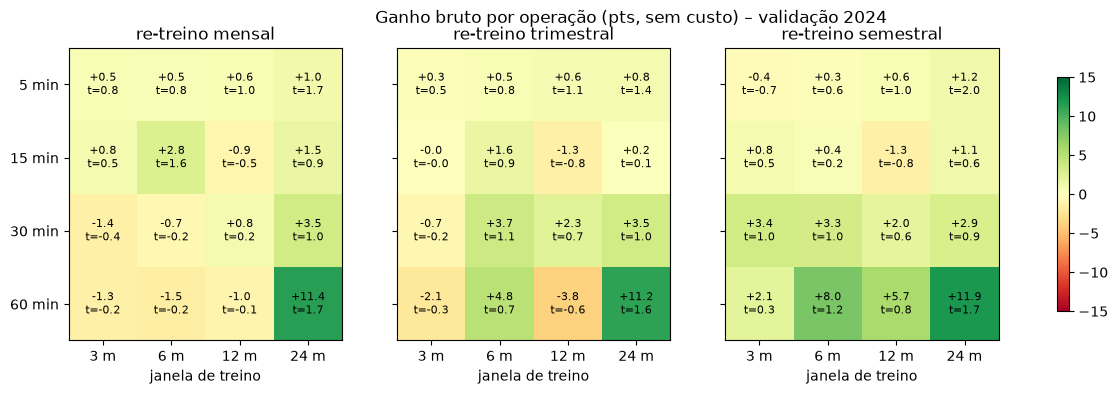

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, f in zip(axs, FREQS):
    g = grade.xs(f, level="re-treino").drop(index=1, level="candle", errors="ignore")
    val = g["ganho bruto pts/op"].unstack("janela_meses"); tt = g["t ganho bruto"].unstack("janela_meses")
    im = a.imshow(val.values, cmap="RdYlGn", vmin=-15, vmax=15, aspect="auto")
    for i in range(val.shape[0]):
        for k in range(val.shape[1]):
            a.text(k, i, f"{val.values[i,k]:+.1f}\nt={tt.values[i,k]:.1f}", ha="center", va="center", fontsize=8)
    a.set_xticks(range(val.shape[1])); a.set_xticklabels([f"{c} m" for c in val.columns])
    a.set_yticks(range(val.shape[0])); a.set_yticklabels([f"{c} min" for c in val.index])
    a.set_title(f"re-treino {f}"); a.set_xlabel("janela de treino")
fig.suptitle("Ganho bruto por operação (pts, sem custo) – validação 2024")
fig.colorbar(im, ax=axs, shrink=.8)
plt.savefig("passo04_grade.png", dpi=120, bbox_inches="tight"); plt.show()

In [7]:
cols_show = ["R² vs naive %", "acerto direção %", "ganho bruto pts/op", "t ganho bruto", "trimestres + (bruto)",
             "líquido pts/op (sempre)", "líquido 20% fortes", "n_ops"]
print("Candidatas pelo critério:")
display(grade[grade["candidata"]].sort_values("ganho bruto pts/op", ascending=False)[cols_show].round(2))
print("Top 8 por t do ganho bruto:")
display(grade.sort_values("t ganho bruto", ascending=False)[cols_show].head(8).round(2))

Candidatas pelo critério:


R² vs naive %  acerto direção %  \
candle janela_meses re-treino                                     
1      12           trimestral          -0.01             51.14   
       6            trimestral          -0.08             51.02   
       3            trimestral          -0.14             50.83   

                                ganho bruto pts/op  t ganho bruto  \
candle janela_meses re-treino                                       
1      12           trimestral                0.27           2.31   
       6            trimestral                0.25           2.16   
       3            trimestral                0.23           2.02   

                                trimestres + (bruto)  líquido pts/op (sempre)  \
candle janela_meses re-treino                                                   
1      12           trimestral                   4.0                    -4.73   
       6            trimestral                   4.0                    -4.75   
       3            trimestral                   4.0                    -4.77   

                                líquido 20% fortes     n_ops  
candle janela_meses re-treino                                 
1      12           trimestral               -4.01  135029.0  
       6            trimestral               -4.07  135029.0  
       3            trimestral               -4.51  135029.0

Top 8 por t do ganho bruto:


R² vs naive %  acerto direção %  \
candle janela_meses re-treino                                     
1      12           trimestral          -0.01             51.14   
       6            trimestral          -0.08             51.02   
5      24           semestral           -0.07             51.47   
1      3            trimestral          -0.14             50.83   
60     24           semestral           -0.39             51.51   
5      24           mensal              -0.04             51.33   
60     24           mensal               0.20             51.76   
15     6            mensal              -0.60             51.11   

                                ganho bruto pts/op  t ganho bruto  \
candle janela_meses re-treino                                       
1      12           trimestral                0.27           2.31   
       6            trimestral                0.25           2.16   
5      24           semestral                 1.16           2.04   
1      3            trimestral                0.23           2.02   
60     24           semestral                11.89           1.74   
5      24           mensal                    0.97           1.71   
60     24           mensal                   11.44           1.67   
15     6            mensal                    2.81           1.65   

                                trimestres + (bruto)  líquido pts/op (sempre)  \
candle janela_meses re-treino                                                   
1      12           trimestral                   4.0                    -4.73   
       6            trimestral                   4.0                    -4.75   
5      24           semestral                    2.0                    -3.84   
1      3            trimestral                   4.0                    -4.77   
60     24           semestral                    4.0                     6.89   
5      24           mensal                       2.0                    -4.03   
60     24           mensal                       4.0                     6.44   
15     6            mensal                       4.0                    -2.19   

                                líquido 20% fortes     n_ops  
candle janela_meses re-treino                                 
1      12           trimestral               -4.01  135029.0  
       6            trimestral               -4.07  135029.0  
5      24           semestral                -2.62   26808.0  
1      3            trimestral               -4.51  135029.0  
60     24           semestral                 7.76    2004.0  
5      24           mensal                   -3.73   26808.0  
60     24           mensal                   16.46    2004.0  
15     6            mensal                    2.04    8769.0

In [8]:
# Qual dimensão pesa mais? média do ganho bruto por nível de cada dimensão (sem 1 min)
g = grade.drop(index=1, level="candle")
pd.concat({d: g.groupby(level=d)[["ganho bruto pts/op", "t ganho bruto"]].mean() for d in ["candle", "janela_meses", "re-treino"]}).round(2)

ganho bruto pts/op  t ganho bruto
candle       5                         0.52           0.92
             15                        0.47           0.27
             30                        1.89           0.55
             60                        3.79           0.55
janela_meses 3                         0.16           0.14
             6                         1.98           0.71
             12                        0.36           0.22
             24                        4.17           1.22
re-treino    mensal                    1.04           0.54
             semestral                 2.62           0.68
             trimestral                1.34           0.51

## 4.3 A janela de 24 meses ficou na borda da grade – e se olhar ainda mais para trás?

Quando o melhor valor está no limite da grade, precisamos testar além dele. Acrescentamos **36 meses** e **todo o histórico** (janela expansiva, desde 10/2020), com re-treino trimestral.

In [9]:
for m in [5, 15, 30, 60]:
    for j in [36, 120]:            # 120 meses > histórico disponível = janela expansiva ("tudo")
        if (m, j, "trimestral") in prevs: continue
        base, cols = bases[m]
        prevs[(m, j, "trimestral")] = rz.walk_forward(base, cols, rz.VALIDACAO, j, "QS")[["prev", "ret_prox", "mov_prox", "close"]]
pd.to_pickle(prevs, ARQ)
grade = pd.DataFrame({k: rz.resumo_wf(v) for k, v in prevs.items()}).T
grade.index.names = ["candle", "janela_meses", "re-treino"]
grade["candidata"] = (grade["ganho bruto pts/op"] > 0) & (grade["t ganho bruto"] >= 2) & (grade["trimestres + (bruto)"] >= 3)
grade = grade.sort_index(); grade.to_csv("saidas/passo04_grade.csv")
grade.xs("trimestral", level="re-treino").drop(index=1, level="candle")[cols_show].round(2)

R² vs naive %  acerto direção %  ganho bruto pts/op  \
candle janela_meses                                                        
5      3                     -0.62             50.89                0.30   
       6                     -0.46             50.71                0.47   
       12                    -0.17             50.77                0.61   
       24                    -0.05             51.32                0.78   
       36                    -0.05             51.01                0.75   
       120                   -0.04             51.19                0.68   
15     3                     -1.04             50.27               -0.03   
       6                     -0.65             50.84                1.58   
       12                    -0.46             50.09               -1.32   
       24                    -0.04             50.08                0.19   
       36                     0.08             50.56                0.98   
       120                   -0.00             49.58               -2.53   
30     3                     -2.27             51.14               -0.75   
       6                     -1.86             51.29                3.73   
       12                    -1.05             51.02                2.33   
       24                    -0.39             50.62                3.47   
       36                    -0.17             51.09                6.28   
       120                   -0.06             51.57                6.31   
60     3                     -2.79             50.81               -2.09   
       6                     -2.46             51.51                4.84   
       12                    -1.83             50.45               -3.77   
       24                    -0.37             51.91               11.16   
       36                     0.05             52.01               12.04   
       120                    0.20             52.17                9.70   

                     t ganho bruto  trimestres + (bruto)  \
candle janela_meses                                        
5      3                      0.52                   2.0   
       6                      0.83                   2.0   
       12                     1.08                   3.0   
       24                     1.37                   2.0   
       36                     1.33                   3.0   
       120                    1.20                   3.0   
15     3                     -0.02                   3.0   
       6                      0.93                   2.0   
       12                    -0.77                   2.0   
       24                     0.11                   2.0   
       36                     0.58                   2.0   
       120                   -1.48                   1.0   
30     3                     -0.22                   1.0   
       6                      1.08                   2.0   
       12                     0.68                   3.0   
       24                     1.01                   2.0   
       36                     1.82                   4.0   
       120                    1.83                   4.0   
60     3                     -0.31                   2.0   
       6                      0.71                   2.0   
       12                    -0.55                   2.0   
       24                     1.63                   4.0   
       36                     1.76                   4.0   
       120                    1.42                   3.0   

                     líquido pts/op (sempre)  líquido 20% fortes    n_ops  
candle janela_meses                                                        
5      3                               -4.70               -4.56  26808.0  
       6                               -4.53               -4.55  26808.0  
       12                              -4.39               -3.12  26808.0  
       24                              -4.22               -3.51  26808.0  
       36                  

## Conclusões do Passo 4

1. **Janela de treino: quanto mais longa, melhor.** É o resultado mais claro da grade: o R² sobe de forma quase monotônica com a janela (60 min: −2,8% com 3 meses → +0,05% com 36 meses). Com sinal fraco, a árvore precisa de muitos exemplos; janelas curtas a fazem decorar ruído. O ganho para de crescer entre 24 e 36 meses – escolhemos **36 meses**.
2. **Frequência de re-treino: quase não importa.** A curva de envelhecimento (4.1) não mostra queda de desempenho nos 6 meses após o treino, e na grade mensal/trimestral/semestral dão resultados parecidos para a mesma janela. Mantemos **trimestral** (mais simples, sem evidência de que mais frequente ajude).
3. **Candle: 60 min é o único que paga o custo operando sempre.** 60 min × 36 meses: ganho bruto de **+12,0 pts/op**, positivo nos **4 trimestres** de 2024, R² = +0,05%, líquido de **+7,0 pts/op** com custo. Segundo lugar: 30 min × 36 meses (+6,3 bruto, 4/4 trimestres, líquido +1,3).
4. **Significância ≠ lucro.** O único caso que passa no critério estatístico (t ≥ 2, ≥ 3 trimestres) é o candle de **1 min** (t = 2,3, 4/4 trimestres) – há sinal real, mas de **0,27 pt** por operação, contra 5 pts de custo. Inútil para ganhar dinheiro.
5. **Cautela:** o t do 60 min é 1,8 (só ~2.000 operações num ano) e testamos 60 combinações – parte do resultado pode ser sorte. O que dá alguma confiança é a **consistência**: 24 e 36 meses e as três frequências apontam na mesma direção, e os 4 trimestres são positivos.

➡️ **Decisão:** seguir com **60 min × janela de 36 meses × re-treino trimestral**, levando **30 min × 36 meses** como alternativa para o Passo 5.
